# Leave-one-reaction-out cross-validation of the combined reference system

**Purpose.** Out-of-sample test of the prediction the reactivity scale actually makes: the rate constant of an
unmeasured combination of two parametrized species. Each of the 187 rate constants of the combined reference system
(SI, section 8.4) is withheld in turn, all 84 reactivity parameters are refitted from the remaining 186 rate constants
with the fitting engine of the full parametrization, and the withheld rate constant is predicted from the refitted
parameters.

**Scope.** This notebook does not repeat the selection of the reference system, the residual pruning, the attachment
of discarded species or the Bayesian bootstrap. It reads the reference system from the metadata workbook of the
full LFER analysis (`lfer_analysis_v2_metadata.xlsx`, sheet `selected_dataset`), verifies that the published fit is
reproduced exactly, and then runs the cross-validation. The fitting engine (`fit_lfer`, `predict_lgk`) is identical to
that of the full analysis.

**Fold classes.** Withholding one rate constant never disconnects a species from the scale (every species of the
reference system has at least two independent partners), but it can leave the species exactly determined instead of
*overdetermined*: a nucleophile defined by exactly three phosphorylating agents is left with two (two equations for
$N_P$ and $s_{N,P}$), and a phosphorylating agent defined by exactly two nucleophiles is left with one (one equation
for $E_P$). Folds are therefore classified as *thresholds intact* (the coverage rules of the selection still hold for
every species after withholding) or *minimum coverage* (the withheld rate constant drops its nucleophile or its
phosphorylating agent to the exactly determined case). The anchor species (Nu5, P7) are exempt, as their fixed
parameters need no coverage.

**Outputs.** `lfer_analysis_loo_parity.png` (parity plot and residual distributions),
`lfer_analysis_loo_results.xlsx` (per-fold results, summary table, largest residuals).


## 0. Configuration

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)

FONTSIZE = 12
mpl.rcParams.update({
    "font.family": "Arial", "font.size": FONTSIZE,
    "axes.titlesize": FONTSIZE, "axes.labelsize": FONTSIZE,
    "xtick.labelsize": FONTSIZE, "ytick.labelsize": FONTSIZE, "legend.fontsize": FONTSIZE,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.size": 4, "ytick.major.size": 4, "axes.linewidth": 0.9,
    "figure.dpi": 110, "savefig.dpi": 150,
})


class CONFIG:
    # --- input: reference system and published fit (metadata workbook of the full LFER analysis) ---
    V2_METADATA_FILE = "lfer_analysis_v2_metadata.xlsx"
    REFERENCE_SHEET = "selected_dataset"      # the 187 rate constants of the combined reference system
    CORE_FIT_SHEET = "core_fit"               # the same rows with the published lg k_calc
    PARAMS_SHEET = "params_core_bootstrap"    # published point estimates of the 84 parameters

    # --- output ---
    LOO_FIG_FILE = "lfer_analysis_loo_parity.png"
    LOO_RESULTS_FILE = "lfer_analysis_loo_results.xlsx"

    # --- model form and anchoring (identical to the full parametrization) ---
    ANCHOR_NUC = "3,4-lutidine"   # reference nucleophile: s_N,P = 1; N_P is fitted
    ANCHOR_ELEC = "P7"            # reference electrophile: E_P = 0

    # --- coverage thresholds of the selection (identical to the full parametrization) ---
    MIN_ELECTROPHILES = 3         # a nucleophile enters a refit only with >=3 electrophiles
    MIN_NUC_PER_ELEC = 2          # a jointly fitted electrophile needs >=2 distinct nucleophiles

    # --- least-squares bounds (identical to the full parametrization) ---
    S_BOUNDS = (0.0, 1.5); N_BOUNDS = (-60.0, 60.0); E_BOUNDS = (-60.0, 60.0)

    # --- reporting ---
    N_LARGEST_RESIDUALS = 8
    TOLERANCE_REPRODUCTION = 1e-3  # max. allowed deviation (lg units) from the published lg k_calc and parameters

## 1. The published reference system

The 187 rate constants are read exactly as selected in the full LFER analysis. Electrophiles are identified by their `P` identifier
(which is also the species key used in the fit), nucleophiles by name with their `Nu` identifier. Duplicate
measurements of the same combination (several literature values, or one literature and one HTE value) are separate
rows, as in the final fit.

In [2]:
sel = pd.read_excel(CONFIG.V2_METADATA_FILE, sheet_name=CONFIG.REFERENCE_SHEET)
core_fit_published = pd.read_excel(CONFIG.V2_METADATA_FILE, sheet_name=CONFIG.CORE_FIT_SHEET)
params_published = pd.read_excel(CONFIG.V2_METADATA_FILE, sheet_name=CONFIG.PARAMS_SHEET)

d_ref = pd.DataFrame({
    "rxn_id": np.arange(len(sel)),
    "nucleophile": sel["nucleophile"].astype(str),
    "nucleophile_id": sel["nucleophile_id"].astype(str),
    "electrophile": sel["electrophile_id"].astype(str),   # P identifier = species key in the fit
    "source": sel["source"].map({"hte_kinetics": "this work", "literature": "literature"}).fillna(sel["source"]),
    "lgk": sel["lgk"].astype(float),
})
assert (core_fit_published[["nucleophile", "electrophile_id"]].values == sel[["nucleophile", "electrophile_id"]].values).all()
d_ref["lgk_calc_published"] = core_fit_published["lgk_calc"].to_numpy(float)

n_E = d_ref.groupby("nucleophile")["electrophile"].nunique()     # phosphorylating agents per nucleophile
n_N = d_ref.groupby("electrophile")["nucleophile"].nunique()     # nucleophiles per phosphorylating agent
pair_count = d_ref.groupby(["nucleophile", "electrophile"]).size()

print(f"Reference system: {len(d_ref)} rate constants, {d_ref.nucleophile.nunique()} nucleophiles, "
      f"{d_ref.electrophile.nunique()} phosphorylating agents, {int((pair_count > 1).sum())} combinations measured more than once")
print(f"Sources: {d_ref.source.value_counts().to_dict()}")
print("Phosphorylating agents per nucleophile:", dict(n_E.value_counts().sort_index()))
print("Nucleophiles per phosphorylating agent:", dict(n_N.value_counts().sort_index()))

Reference system: 187 rate constants, 35 nucleophiles, 14 phosphorylating agents, 15 combinations measured more than once
Sources: {'literature': 116, 'this work': 71}
Phosphorylating agents per nucleophile: {3: 10, 4: 9, 5: 4, 6: 8, 7: 2, 10: 2}
Nucleophiles per phosphorylating agent: {2: 4, 4: 1, 10: 1, 11: 1, 13: 1, 15: 1, 18: 3, 22: 1, 31: 1}


## 2. LFER fitting engine

Identical to the fitting engine of the full LFER analysis: bounded least squares for
$\lg k_2 = s_{N,P} \cdot E_P + N_P$ with $s_{N,P}(\mathrm{Nu5}) = 1$ and $E_P(\mathrm{P7}) = 0$.


In [3]:
def fit_lfer(data, cfg=CONFIG, anchor_nuc=None, anchor_elec=None, weights=None):
    anchor_nuc = anchor_nuc or cfg.ANCHOR_NUC
    anchor_elec = anchor_elec or cfg.ANCHOR_ELEC
    d = data.reset_index(drop=True)
    nucs, elecs = sorted(d["nucleophile"].unique()), sorted(d["electrophile"].unique())
    if anchor_nuc not in nucs:
        raise ValueError(f"anchor nucleophile {anchor_nuc!r} not in data")
    if anchor_elec not in elecs:
        raise ValueError(f"anchor electrophile {anchor_elec!r} not in data")

    y, ni, ei = d["lgk"].to_numpy(), d["nucleophile"].to_numpy(), d["electrophile"].to_numpy()
    sw = np.sqrt(np.ones(len(d)) if weights is None else np.asarray(weights, float))
    E0 = {e: d.loc[d.electrophile == e, "lgk"].mean() for e in elecs}
    E0_anchor = E0[anchor_elec]

    free_s_n = [n for n in nucs if n != anchor_nuc]
    free_e = [e for e in elecs if e != anchor_elec]
    sdx = {n: k for k, n in enumerate(free_s_n)}
    ndx = {n: k for k, n in enumerate(nucs)}
    edx = {e: k for k, e in enumerate(free_e)}
    ns, nn, ne = len(free_s_n), len(nucs), len(free_e)

    N0 = []
    for n in nucs:
        at_anchor_e = d[(d["nucleophile"] == n) & (d["electrophile"] == anchor_elec)]["lgk"]
        N0.append(float(at_anchor_e.mean() if len(at_anchor_e) else d.loc[d.nucleophile == n, "lgk"].mean()))
    x0 = np.r_[np.ones(ns), N0, [E0[e] - E0_anchor for e in free_e]]
    lo = np.r_[np.full(ns, cfg.S_BOUNDS[0]), np.full(nn, cfg.N_BOUNDS[0]), np.full(ne, cfg.E_BOUNDS[0])]
    hi = np.r_[np.full(ns, cfg.S_BOUNDS[1]), np.full(nn, cfg.N_BOUNDS[1]), np.full(ne, cfg.E_BOUNDS[1])]
    x0 = np.clip(x0, lo + 1e-9, hi - 1e-9)

    is_anchor_n = (ni == anchor_nuc)
    is_anchor_e = (ei == anchor_elec)
    s_pos = np.array([sdx.get(n, 0) for n in ni])
    n_pos = np.array([ndx[n] for n in ni])
    e_pos = np.array([edx.get(e, 0) for e in ei])

    def resid(x):
        s, N, E = x[:ns], x[ns:ns+nn], x[ns+nn:]
        sv = np.where(is_anchor_n, 1.0, s[s_pos])
        Ev = np.where(is_anchor_e, 0.0, E[e_pos])
        Nv = N[n_pos]
        return sw * (sv * Ev + Nv - y)

    res = least_squares(resid, x0, bounds=(lo, hi), method="trf", max_nfev=30000)
    s, N, E = res.x[:ns], res.x[ns:ns+nn], res.x[ns+nn:]
    rows = []
    for k, n in enumerate(nucs):
        rows.append(dict(type="nucleophile", species=n, parameter="N", estimate=N[k]))
        rows.append(dict(type="nucleophile", species=n, parameter="s",
                         estimate=1.0 if n == anchor_nuc else s[sdx[n]]))
    rows.append(dict(type="electrophile", species=anchor_elec, parameter="E", estimate=0.0))
    for k, e in enumerate(free_e):
        rows.append(dict(type="electrophile", species=e, parameter="E", estimate=E[k]))

    params = pd.DataFrame(rows)
    fitted = _apply_params(d, params)
    r = fitted["residual"].to_numpy(); yv = fitted["lgk"].to_numpy()
    ss_res, ss_tot = float(np.sum(r**2)), float(np.sum((yv - yv.mean())**2))
    metrics = dict(n=len(d), n_nuc=len(nucs), n_elec=len(elecs),
                   rmse=float(np.sqrt(np.mean(r**2))), mae=float(np.mean(np.abs(r))),
                   r2=(1 - ss_res/ss_tot) if ss_tot > 0 else np.nan, success=bool(res.success))
    return params, fitted, metrics, res


def _param_lookup(params):
    return params.set_index(["type", "species", "parameter"])["estimate"].to_dict()

def predict_lgk(params, nucleophile, electrophile):
    p = _param_lookup(params) if isinstance(params, pd.DataFrame) else params
    N = p[("nucleophile", nucleophile, "N")]
    E = p[("electrophile", electrophile, "E")]
    return N + p[("nucleophile", nucleophile, "s")] * E

def _apply_params(data, params):
    p = _param_lookup(params)
    out = data.copy()
    out["lgk_calc"] = [predict_lgk(p, n, e) for n, e in zip(data["nucleophile"], data["electrophile"])]
    out["residual"] = out["lgk"] - out["lgk_calc"]
    return out

## 3. Reproduction of the published fit

Before the cross-validation, the engine is run once on all 187 rate constants. The resulting $\lg k_{\mathrm{calc}}$ and
parameters must agree with the published values (sheets `core_fit` and `params_core_bootstrap`) to within numerical
tolerance; otherwise the notebook stops.

In [4]:
params_full, fitted_full, metrics_full, _ = fit_lfer(d_ref)
dev_lgk = float(np.max(np.abs(fitted_full["lgk_calc"].to_numpy() - d_ref["lgk_calc_published"].to_numpy())))

pub = params_published.copy()
pub["species_key"] = np.where(pub["type"] == "electrophile", pub["species_id"].astype(str), pub["species"].astype(str))
merged = params_full.merge(pub[["type", "species_key", "parameter", "point"]],
                           left_on=["type", "species", "parameter"], right_on=["type", "species_key", "parameter"], how="left")
dev_par = float(np.nanmax(np.abs(merged["estimate"] - merged["point"])))
n_unmatched = int(merged["point"].isna().sum())

print(f"Full refit: n = {metrics_full['n']}, RMSE = {metrics_full['rmse']:.4f}, R2 = {metrics_full['r2']:.4f}, "
      f"{metrics_full['n_nuc']} nucleophiles, {metrics_full['n_elec']} phosphorylating agents, {len(params_full)} parameters")
print(f"Max. deviation from published lg k_calc: {dev_lgk:.2e};  from published parameters: {dev_par:.2e} ({n_unmatched} unmatched)")
if dev_lgk > CONFIG.TOLERANCE_REPRODUCTION or dev_par > CONFIG.TOLERANCE_REPRODUCTION or n_unmatched:
    raise RuntimeError("The published fit is not reproduced; check the input sheets and the fitting engine.")
print("Published fit reproduced.")
in_sample = fitted_full.set_index("rxn_id")["lgk_calc"]

Full refit: n = 187, RMSE = 0.1404, R2 = 0.9953, 35 nucleophiles, 14 phosphorylating agents, 84 parameters
Max. deviation from published lg k_calc: 1.02e-08;  from published parameters: 1.61e-08 (0 unmatched)
Published fit reproduced.


## 4. Leave-one-reaction-out cross-validation

For every fold the species set is unchanged (the withheld reaction's species keep their other reactions), the anchors
are the same, and no selection or pruning is repeated. The remaining coverage of the two species of the withheld
reaction is recorded; a duplicate measurement of the same combination keeps the pair, so the coverage does not drop.

In [5]:
t0 = time.time(); loo_rows = []
for j in range(len(d_ref)):
    r = d_ref.iloc[j]
    train = d_ref.drop(index=j)
    p_j, _, m_j, _ = fit_lfer(train)
    pred = predict_lgk(p_j, r["nucleophile"], r["electrophile"])
    dup = pair_count[(r["nucleophile"], r["electrophile"])] > 1
    nE_left = int(n_E[r["nucleophile"]] - (0 if dup else 1))
    nN_left = int(n_N[r["electrophile"]] - (0 if dup else 1))
    nuc_ok = (r["nucleophile"] == CONFIG.ANCHOR_NUC) or nE_left >= CONFIG.MIN_ELECTROPHILES
    elec_ok = (r["electrophile"] == CONFIG.ANCHOR_ELEC) or nN_left >= CONFIG.MIN_NUC_PER_ELEC
    if nuc_ok and elec_ok:
        fold_class = "thresholds intact"
    elif not nuc_ok and not elec_ok:
        fold_class = "nucleophile and phosphorylating agent at minimum coverage"
    elif not nuc_ok:
        fold_class = "nucleophile at minimum coverage"
    else:
        fold_class = "phosphorylating agent at minimum coverage"
    loo_rows.append(dict(
        rxn_id=int(r["rxn_id"]), nucleophile=r["nucleophile"], nucleophile_id=r["nucleophile_id"],
        electrophile=r["electrophile"], source=r["source"], lgk=r["lgk"],
        lgk_calc_in_sample=in_sample[r["rxn_id"]], lgk_calc_loo=pred,
        residual_in_sample=r["lgk"] - in_sample[r["rxn_id"]], residual_loo=r["lgk"] - pred,
        n_elec_defining_nucleophile=int(n_E[r["nucleophile"]]), n_elec_remaining=nE_left,
        n_nuc_defining_electrophile=int(n_N[r["electrophile"]]), n_nuc_remaining=nN_left,
        thresholds_intact=bool(nuc_ok and elec_ok), fold_class=fold_class,
        fit_success=m_j["success"], train_rmse=m_j["rmse"]))
    if (j + 1) % 50 == 0 or j + 1 == len(d_ref):
        print(f"  fold {j + 1}/{len(d_ref)}  ({time.time() - t0:.0f} s)")
loo = pd.DataFrame(loo_rows)
assert loo["fit_success"].all(), "a leave-one-out refit did not converge"
print(f"\nFold classes: {loo['fold_class'].value_counts().to_dict()}")

  fold 50/187  (1 s)


  fold 100/187  (3 s)


  fold 150/187  (4 s)


  fold 187/187  (5 s)

Fold classes: {'thresholds intact': 149, 'nucleophile at minimum coverage': 30, 'phosphorylating agent at minimum coverage': 8}


## 5. Summary

Prediction errors by fold class and by the coverage of the nucleophile of the withheld reaction in the full reference
system. "Within 0.5 lg" and "within 1.0 lg" are the fractions of withheld rate constants predicted within a factor of
three and within one order of magnitude.

In [6]:
def _rmse(x):
    return float(np.sqrt(np.mean(np.asarray(x, float) ** 2)))


def _summ(df, label):
    return dict(subset=label, n=len(df),
                rmse_in_sample=_rmse(df["residual_in_sample"]), rmse_loo=_rmse(df["residual_loo"]),
                mae_loo=float(np.mean(np.abs(df["residual_loo"]))), bias_loo=float(np.mean(df["residual_loo"])),
                within_0p5=float(np.mean(np.abs(df["residual_loo"]) <= 0.5)),
                within_1p0=float(np.mean(np.abs(df["residual_loo"]) <= 1.0)),
                max_abs_loo=float(np.max(np.abs(df["residual_loo"]))))


intact = loo["thresholds_intact"]
nuc_min = loo["fold_class"].str.startswith("nucleophile")
elec_min = loo["fold_class"] == "phosphorylating agent at minimum coverage"
nE_full = loo["n_elec_defining_nucleophile"]
loo_summary = pd.DataFrame([
    _summ(loo, "all folds"),
    _summ(loo[intact], "thresholds intact"),
    _summ(loo[nuc_min], "nucleophile at minimum coverage (2 phosphorylating agents left)"),
    _summ(loo[elec_min], "phosphorylating agent at minimum coverage (1 nucleophile left)"),
    _summ(loo[nE_full == 4], "nucleophile defined by 4 phosphorylating agents"),
    _summ(loo[nE_full >= 5], "nucleophile defined by >= 5 phosphorylating agents"),
])
print("Leave-one-reaction-out cross-validation of the reference system:")
display(loo_summary.round(3))

# supplementary statistics: by origin of the withheld rate constant
by_source = pd.DataFrame([_summ(g, k) for k, g in loo.groupby("source")]).set_index("subset")
print("\nBy origin of the withheld rate constant:")
display(by_source[["n", "rmse_loo", "within_0p5", "within_1p0"]].round(3))
print(f"Nucleophiles defined by exactly 3 phosphorylating agents: {int((nE_full == 3).sum())} folds "
      f"(identical to the 'nucleophile at minimum coverage' class: {bool(((nE_full == 3) == nuc_min).all())})")

largest = (loo.assign(abs_loo=loo["residual_loo"].abs()).sort_values("abs_loo", ascending=False)
           .head(CONFIG.N_LARGEST_RESIDUALS)
           [["nucleophile", "nucleophile_id", "electrophile", "source", "lgk", "lgk_calc_in_sample", "lgk_calc_loo",
             "residual_loo", "n_elec_remaining", "fold_class"]])
print(f"\n{CONFIG.N_LARGEST_RESIDUALS} largest leave-one-out residuals:")
display(largest.round(3))

Leave-one-reaction-out cross-validation of the reference system:


,subset,n,rmse_in_sample,rmse_loo,mae_loo,bias_loo,within_0p5,within_1p0,max_abs_loo
0,all folds,187,0.140,0.477,0.271,-0.013,0.920,0.957,3.288
1,thresholds intact,149,0.149,0.319,0.224,0.010,0.946,0.980,1.696
2,nucleophile at minimum coverage (2 phosphoryla...,30,0.103,0.951,0.529,-0.127,0.767,0.833,3.288
3,phosphorylating agent at minimum coverage (1 n...,8,0.084,0.192,0.184,0.002,1.000,1.000,0.257
4,nucleophile defined by 4 phosphorylating agents,37,0.147,0.473,0.301,0.062,0.838,0.946,1.696
5,nucleophile defined by >= 5 phosphorylating ag...,120,0.146,0.244,0.197,-0.007,0.983,0.992,1.015



By origin of the withheld rate constant:


,n,rmse_loo,within_0p5,within_1p0
subset,,,,
literature,116,0.533,0.914,0.940
this work,71,0.367,0.930,0.986


Nucleophiles defined by exactly 3 phosphorylating agents: 30 folds (identical to the 'nucleophile at minimum coverage' class: True)

8 largest leave-one-out residuals:


,nucleophile,nucleophile_id,electrophile,source,lgk,lgk_calc_in_sample,lgk_calc_loo,residual_loo,n_elec_remaining,fold_class
140,4-dimethylaminopyridine,Nu30,P8,literature,-1.951,-1.911,1.337,-3.288,2,nucleophile at minimum coverage
145,ethylenediamine,Nu47,P8,literature,-2.538,-2.505,0.184,-2.721,2,nucleophile at minimum coverage
62,4-morpholinopyridine,Nu11,P9,this work,-3.865,-3.876,-5.833,1.968,2,nucleophile at minimum coverage
120,pyrrolidine,Nu16,P30,literature,0.792,0.720,-0.903,1.696,3,thresholds intact
100,cyclohexylamine,Nu15,P25,literature,-1.022,-1.124,-2.563,1.542,3,thresholds intact
104,4-cyanopyridine,Nu10,P30,literature,0.190,0.222,1.560,-1.370,2,nucleophile at minimum coverage
151,ch3co2–,Nu56,P8,literature,-6.149,-6.171,-7.244,1.096,2,nucleophile at minimum coverage
168,3-methoxypyridine,Nu7,P31,literature,-0.292,-0.129,0.723,-1.015,5,thresholds intact


## 6. Figure: parity plot and residual distributions

Left: experimental versus leave-one-out predicted $\lg k_2$; filled symbols are folds with intact thresholds, open
symbols folds in which a species is at minimum coverage. Right: in-sample residuals of the full fit (grey) and
leave-one-out residuals, stacked by fold class, for the same 187 reactions.


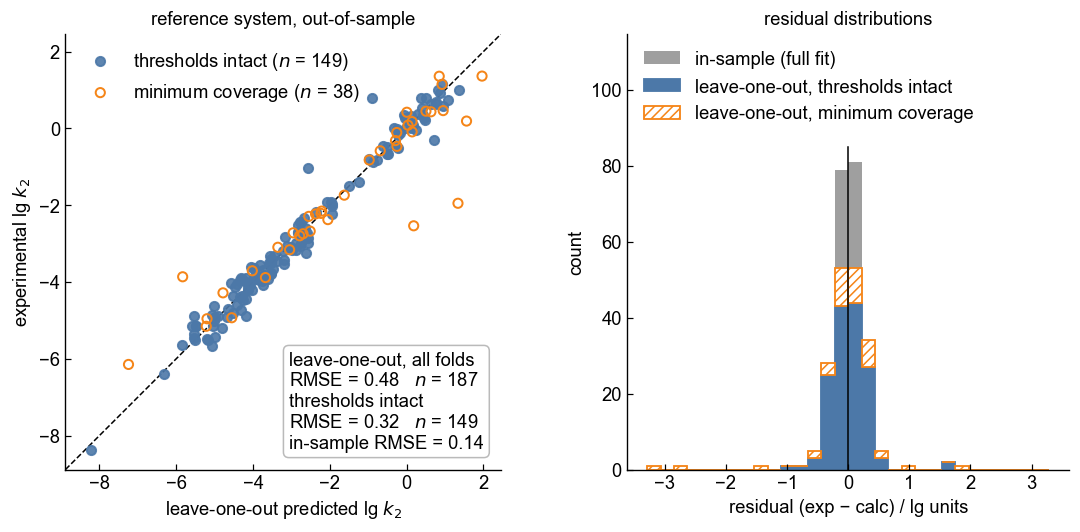

Wrote lfer_analysis_loo_parity.png


In [7]:
COL_INTACT, COL_MIN, COL_INSAMPLE = "#4C78A8", "#F58518", "#7F7F7F"

fig, ax = plt.subplots(1, 2, figsize=(10.4, 5.0), gridspec_kw=dict(width_ratios=[1.25, 1]))

# --- left: parity ---
a = ax[0]
for mask, color, filled, label in [(intact, COL_INTACT, True, f"thresholds intact ($n$ = {int(intact.sum())})"),
                                   (~intact, COL_MIN, False, f"minimum coverage ($n$ = {int((~intact).sum())})")]:
    a.scatter(loo.loc[mask, "lgk_calc_loo"], loo.loc[mask, "lgk"], s=36, marker="o",
              facecolors=color if filled else "none", edgecolors=color, linewidths=1.3, alpha=0.9 if filled else 1.0,
              label=label, zorder=3)
vals = np.r_[loo["lgk_calc_loo"], loo["lgk"]]
lo_, hi_ = vals.min() - 0.5, vals.max() + 0.5
a.plot([lo_, hi_], [lo_, hi_], "k--", lw=1, zorder=2)
a.set_xlim(lo_, hi_); a.set_ylim(lo_, hi_); a.set_aspect("equal", adjustable="box")
a.set_xlabel("leave-one-out predicted lg $k_2$"); a.set_ylabel("experimental lg $k_2$")
a.set_title("reference system, out-of-sample")
s_all, s_int = loo_summary.iloc[0], loo_summary.iloc[1]
a.text(0.96, 0.04,
       f"leave-one-out, all folds\nRMSE = {s_all.rmse_loo:.2f}   $n$ = {int(s_all.n)}\n"
       f"thresholds intact\nRMSE = {s_int.rmse_loo:.2f}   $n$ = {int(s_int.n)}\n"
       f"in-sample RMSE = {s_all.rmse_in_sample:.2f}",
       transform=a.transAxes, va="bottom", ha="right", multialignment="left", bbox=dict(boxstyle="round", fc="white", ec="0.7", alpha=0.9))
a.legend(loc="upper left", frameon=False)
for side in ("top", "right"):
    a.spines[side].set_visible(False)

# --- right: residual distributions ---
b = ax[1]
lim = max(1.0, float(loo["residual_loo"].abs().max()))
bins = np.linspace(-lim, lim, 31)
b.hist(loo["residual_in_sample"], bins=bins, color=COL_INSAMPLE, alpha=0.75, label="in-sample (full fit)")
_, _, patches = b.hist([loo.loc[intact, "residual_loo"], loo.loc[~intact, "residual_loo"]], bins=bins, stacked=True,
                       color=[COL_INTACT, "white"], linewidth=1.2,
                       label=["leave-one-out, thresholds intact", "leave-one-out, minimum coverage"])
for p_ in patches[0]:
    p_.set_edgecolor(COL_INTACT)
for p_ in patches[1]:
    p_.set_hatch("////"); p_.set_edgecolor(COL_MIN)
b.set_xlabel("residual (exp − calc) / lg units"); b.set_ylabel("count")
y_bars = b.get_ylim()[1]
b.set_ylim(0, 1.35 * y_bars)                       # headroom so the legend sits above the central bars
b.plot([0, 0], [0, y_bars], color="k", lw=1, zorder=1)   # zero line, clipped below the legend
b.legend(frameon=False, loc="upper left")
b.set_title("residual distributions")
for side in ("top", "right"):
    b.spines[side].set_visible(False)

plt.tight_layout()
fig.savefig(CONFIG.LOO_FIG_FILE, dpi=300, bbox_inches="tight")
plt.show()
print(f"Wrote {CONFIG.LOO_FIG_FILE}")

## 7. Export

In [8]:
with pd.ExcelWriter(CONFIG.LOO_RESULTS_FILE) as xw:
    loo.sort_values("residual_loo", key=np.abs, ascending=False).to_excel(xw, sheet_name="loo_folds", index=False)
    loo_summary.to_excel(xw, sheet_name="loo_summary", index=False)
    by_source.reset_index().to_excel(xw, sheet_name="loo_by_source", index=False)
    largest.to_excel(xw, sheet_name="largest_residuals", index=False)
    pd.DataFrame({"item": ["input", "reference sheet", "n_rate_constants", "n_nucleophiles", "n_electrophiles",
                           "n_parameters", "rmse_in_sample", "r2_in_sample", "anchor_nucleophile", "anchor_electrophile",
                           "min_electrophiles_per_nucleophile", "min_nucleophiles_per_electrophile"],
                  "value": [CONFIG.V2_METADATA_FILE, CONFIG.REFERENCE_SHEET, len(d_ref), d_ref.nucleophile.nunique(),
                            d_ref.electrophile.nunique(), len(params_full), metrics_full["rmse"], metrics_full["r2"],
                            CONFIG.ANCHOR_NUC, CONFIG.ANCHOR_ELEC, CONFIG.MIN_ELECTROPHILES, CONFIG.MIN_NUC_PER_ELEC]}
                 ).to_excel(xw, sheet_name="README", index=False)
print(f"Wrote {CONFIG.LOO_RESULTS_FILE}")

Wrote lfer_analysis_loo_results.xlsx
